### Packages!

In [2]:
# pip install numpy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from sklearn.cluster import KMeans

### Generating a dataset

In [3]:
np.random.seed(42)
# number of data points per cluster
n = 100

# top cluster 
x1 = np.random.randn(n) * 3.5  # wide spread in x
y1 = np.random.randn(n) * 0.3 + 3  # narrow spread in y, centered at y=3

# lower left cluster
x2 = np.random.randn(n) * 0.7 - 3  # centered at x=-3
y2 = np.random.randn(n) * 0.7 - 2  # centered at y=-2

# lower right cluster
x3 = np.random.randn(n) * 0.7 + 3  # centered at x=3
y3 = np.random.randn(n) * 0.7 - 2  # centered at y=-2

# Combine all clusters
x = np.concatenate([x1, x2, x3])
y = np.concatenate([y1, y2, y3])

# TODO: create a pandas table for the x and y points generated above. Hint: utilize DataFrame object.
df = pd.DataFrame({"x": x, "y": y})
print(df)
print(df.shape)
# TODO: set X equal to the values of the x and y columns of df (hint: this is a numpy method)
X = df[["x", "y"]].values

            x         y
0    1.738500  2.575389
1   -0.483925  2.873806
2    2.266910  2.897186
3    5.330604  2.759317
4   -0.819537  2.951614
..        ...       ...
295  3.377237 -2.357011
296  2.273928 -2.188912
297  2.866763 -2.685135
298  2.387067 -2.311005
299  2.032040 -1.735890

[300 rows x 2 columns]
(300, 2)


### Vizualizing the dataset

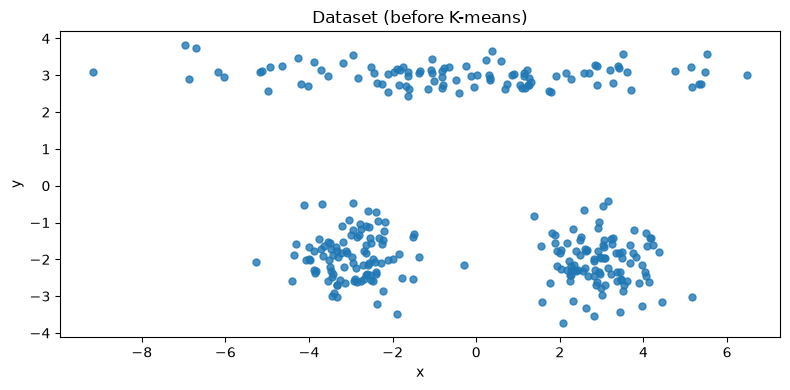

In [4]:
plt.figure(figsize=(8, 4))
plt.scatter(df["x"], df["y"], s=25, alpha=0.8)
plt.xlabel("x"); plt.ylabel("y")
plt.title("Dataset (before K-means)")
plt.tight_layout()
plt.show()

### TODO: Predictions

1. Describe the shape of the data.

2. What shape of data is optimal for K-Means?

3. Do you think this dataset is optimal for K-means?


### TODO: Creating a K-Means Object

In [5]:
# TODO: initialize a KMeans object using scikit-learn's KMeans class. Use random state 42 and lloyd's algorithm
kmeans = KMeans(n_clusters=3, random_state=42, algorithm='lloyd')
# TODO: use the fit_predict method on the previously generated data set (X).
y_km = kmeans.fit_predict(X)

### Running K-Means!

In [6]:
history = []
history.append((kmeans.cluster_centers_.copy(), y_km.copy()))
centroids = kmeans.cluster_centers_.copy()
labels = y_km.copy()

# max number of iterations we will allow
max_steps = 300
for _ in range(max_steps - 1):
    # intializing new KMeans object
    km = KMeans(
        n_clusters=kmeans.n_clusters,
        init=centroids,
        max_iter=1,
        n_init=1,
        random_state=kmeans.random_state,
        algorithm=kmeans.algorithm,
    )
    # fitting K-Means on our data set
    km.fit(X)
    # get new centers
    new_c = km.cluster_centers_
    # get new vertical axis coordinates
    new_l = km.predict(X)
    # check if we have converged
    if np.allclose(centroids, new_c):
        break
    # set new centroid and vertical-axis coordinates for next iteration
    centroids, labels = new_c, new_l
    history.append((centroids.copy(), labels.copy()))

### Animating Iterations of KMeans

In [7]:
from IPython.display import HTML

# intializing the plots
fig, ax = plt.subplots(figsize=(8, 4))
# setting x and y axis limits
ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
# create scatter plots using points computed in previous block
scatter = ax.scatter(X[:, 0], X[:, 1], c=history[0][1], cmap="viridis", s=25, alpha=0.8)

# plotting centroids
cents = ax.scatter(
    history[0][0][:, 0], history[0][0][:, 1],
    c="red", s=200, marker="X", edgecolors="black", linewidths=2, zorder=5,
)
ax.set_xlabel("x"); ax.set_ylabel("y")
title = ax.set_title("Iteration 0")

# iterating len(history) number of times
def update(frame):
    centroids, labels = history[frame]
    scatter.set_array(labels)
    cents.set_offsets(centroids)
    title.set_text(f"Iteration {frame}")
    return scatter, cents, title

anim = animation.FuncAnimation(
    fig, update, frames=len(history), interval=400, blit=True,
)
plt.close(fig)
HTML(anim.to_jshtml())

### TODO: Observations

1. Does the algorithm converge to an optimal solution?

2. How would you describe the behavior of the algorithm through the iterations?

3. What about K-Means makes it handle this shape of data poorly (hint: think of the cost function)(?

### TODO: Bonus!

Consider varying the distance between the elongated cluster and the other two clusters.
1. What is the minimum distance between the clusters such that K-means "optimally" identifies the 3 clusters?
